# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [17]:
# Install model-building dependencies compatible with the Python 3.9 notebook environment
%pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.9.4 seaborn==0.13.2 joblib==1.4.2 requests==2.32.4 -q

You should consider upgrading via the '/Users/raghu/Python_Projects/Multi_Agentic_AI/.venv/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [18]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Regression models
from sklearn.ensemble import (
    BaggingRegressor,
    RandomForestRegressor,
    AdaBoostRegressor,
    GradientBoostingRegressor,
)
from sklearn.tree import DecisionTreeRegressor

# Model metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error,
)

# Pipeline and preprocessing
from sklearn.compose import make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Serialization
import joblib
from pathlib import Path

# OS and API libraries
import os
import requests

# **Loading the dataset**

In [19]:
DATA_PATH = "SuperKart.csv"

try:
    superkart = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    # Run this notebook from /Users/raghu/Python_Projects/Multi_Agentic_AI
    superkart = pd.read_csv("/Users/raghu/Downloads/SuperKart.csv")

print("Dataset shape:", superkart.shape)
superkart.head()

Dataset shape: (8763, 12)


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


# **Data Overview**

In [ ]:
missing_counts = superkart.isna().sum()
quality_table = pd.DataFrame({
    "Missing Values": missing_counts,
    "Missing Percentage": (missing_counts / len(superkart) * 100).round(2),
    "Unique Values": superkart.nunique(),
})

print("Rows:", superkart.shape[0], "Columns:", superkart.shape[1])
print("Columns with missing values:", int((missing_counts > 0).sum()))
print("Total missing cells:", int(missing_counts.sum()))
print("Duplicate rows:", superkart.duplicated().sum())

display(quality_table)
print("Statistical summary:")
display(superkart.describe(include="all").T)

Rows: 8763 Columns: 12
Duplicate rows: 0
Missing values: 0

Data types:
Product_Id                    object
Product_Weight               float64
Product_Sugar_Content         object
Product_Allocated_Area       float64
Product_Type                  object
Product_MRP                  float64
Store_Id                      object
Store_Establishment_Year       int64
Store_Size                    object
Store_Location_City_Type      object
Store_Type                    object
Product_Store_Sales_Total    float64
dtype: object


,Missing Values,Unique Values
Product_Id,0,8763
Product_Weight,0,1113
Product_Sugar_Content,0,4
Product_Allocated_Area,0,228
Product_Type,0,16
Product_MRP,0,6100
Store_Id,0,4
Store_Establishment_Year,0,4
Store_Size,0,3
Store_Location_City_Type,0,3


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product_Id,8763,8763,FD6114,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Weight,8763.0,NaN,NaN,NaN,12.653792,2.21732,4.0,11.15,12.66,14.18,22.0
Product_Sugar_Content,8763,4,Low Sugar,4885,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_Allocated_Area,8763.0,NaN,NaN,NaN,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_Type,8763,16,Fruits and Vegetables,1249,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product_MRP,8763.0,NaN,NaN,NaN,147.032539,30.69411,31.0,126.16,146.74,167.585,266.0
Store_Id,8763,4,OUT004,4676,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Establishment_Year,8763.0,NaN,NaN,NaN,2002.032751,8.388381,1987.0,1998.0,2009.0,2009.0,2009.0
Store_Size,8763,3,Medium,6025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store_Location_City_Type,8763,3,Tier 2,6262,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Data Overview — Observation**

- The dataset contains 8,763 rows and 12 columns.
- The missing-value check confirms that the total number of missing cells is **0**; therefore, no column has missing values.
- `NaN` values shown in `describe(include="all")` are summary-statistic placeholders. For example, mean and standard deviation are not applicable to text columns, while minimum and maximum are not applicable to categorical columns.
- `NaN` in the descriptive summary does **not** mean that a corresponding data cell is missing. The dedicated `Missing Values` column above is the authoritative missing-data check.
- `Product_Store_Sales_Total` is numerical and suitable for a supervised regression problem.

# **Exploratory Data Analysis (EDA)**

## Univariate Analysis

In [ ]:
numeric_cols = superkart.select_dtypes(include=np.number).columns

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.histplot(superkart["Product_Store_Sales_Total"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribution of Product-Store Sales")

sns.histplot(superkart["Product_MRP"], kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Distribution of Product MRP")

sns.boxplot(data=superkart, x="Store_Type", y="Product_Store_Sales_Total", ax=axes[1, 0])
axes[1, 0].set_title("Sales Distribution by Store Type")
axes[1, 0].tick_params(axis="x", rotation=25)

sns.countplot(data=superkart, x="Store_Location_City_Type", ax=axes[1, 1])
axes[1, 1].set_title("Store Count by City Tier")
plt.tight_layout()
plt.show()

**Univariate Analysis — Observation**

- Product-store sales are right-skewed, with most observations concentrated in the middle range and fewer high-sales products.
- MRP varies across a wide range, making it a potentially strong predictor of sales.
- The distribution of observations is uneven across store types and city tiers, so categorical store characteristics may contribute meaningful differences in model predictions.

## Bivariate Analysis

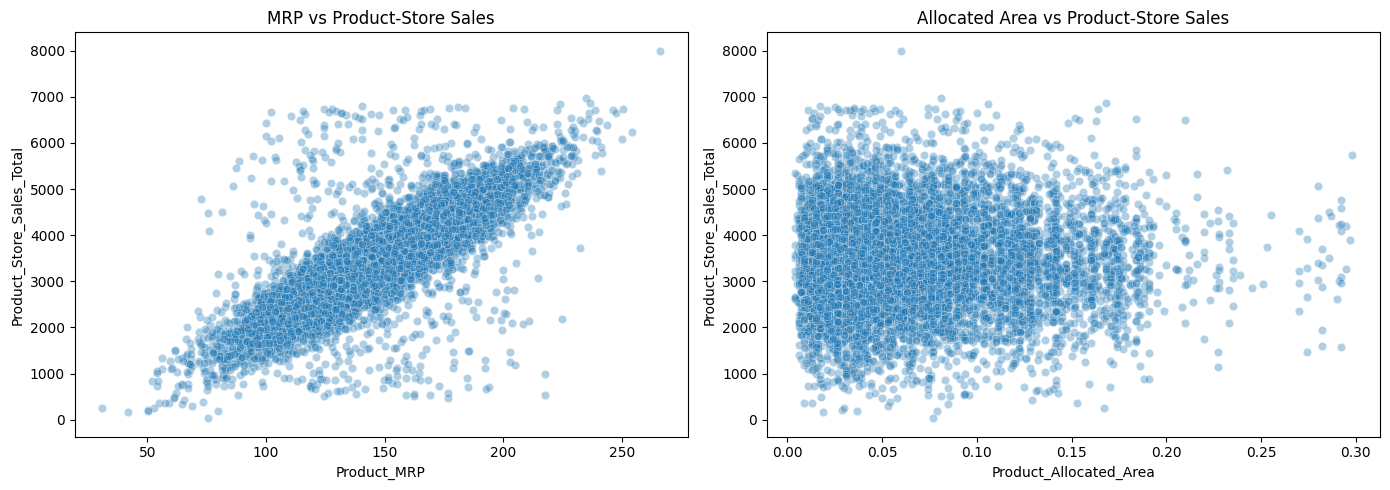

NameError: name 'numeric_cols' is not defined

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=superkart, x="Product_MRP", y="Product_Store_Sales_Total", alpha=0.35, ax=axes[0])
axes[0].set_title("MRP vs Product-Store Sales")

sns.scatterplot(data=superkart, x="Product_Allocated_Area", y="Product_Store_Sales_Total", alpha=0.35, ax=axes[1])
axes[1].set_title("Allocated Area vs Product-Store Sales")
plt.tight_layout()
plt.show()

corr = superkart[numeric_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Feature Correlation")
plt.show()

**Bivariate Analysis — Observation**

- MRP shows a visible positive relationship with product-store sales.
- Allocated display area appears to interact with store and product characteristics rather than having a simple standalone relationship with sales.
- The correlation analysis confirms that model performance is likely to benefit from combining numerical, categorical, and engineered features rather than relying on a single variable.

# **Data Preprocessing**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

superkart["Product_Sugar_Content"] = superkart["Product_Sugar_Content"].replace({"reg": "Regular"})
superkart["Product_Id_char"] = superkart["Product_Id"].astype(str).str[:2]
superkart["Store_Age_Years"] = 2026 - superkart["Store_Establishment_Year"]

perishable_types = {"Breads", "Breakfast", "Dairy", "Frozen Foods", "Fruits and Vegetables", "Meat", "Seafood", "Starchy Foods"}
superkart["Product_Type_Category"] = superkart["Product_Type"].apply(
    lambda value: "Perishables" if value in perishable_types else "Non Perishables"
)

feature_columns = [
    "Product_Weight", "Product_Sugar_Content", "Product_Allocated_Area", "Product_MRP",
    "Store_Size", "Store_Location_City_Type", "Store_Type", "Product_Id_char",
    "Store_Age_Years", "Product_Type_Category"
]
X = superkart[feature_columns]
y = superkart["Product_Store_Sales_Total"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
numeric_columns = ["Product_Weight", "Product_Allocated_Area", "Product_MRP", "Store_Age_Years"]
categorical_columns = [c for c in feature_columns if c not in numeric_columns]

preprocessor = make_column_transformer(
    (Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_columns),
    (Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), categorical_columns),
)

print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (7010, 10) Test shape: (1753, 10)


**Data Preprocessing — Observation**

- The inconsistent `reg` value in the sugar-content field is standardized to `Regular`.
- Product ID prefixes, store age, and perishability categories are derived to provide meaningful business features.
- Numerical columns are median-imputed and standardized; categorical columns are most-frequent-imputed and one-hot encoded.
- The 80/20 train-test split and full preprocessing pipeline prevent data leakage and preserve consistency for deployment.

# **Model Building**

## Define functions for Model Evaluation

In [4]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

The ML models selected for this regression problem are:

1. **Random Forest Regressor** - captures nonlinear relationships and interactions among product and store attributes.
2. **Gradient Boosting Regressor** - builds sequential trees to correct prior residual errors and often provides strong generalization.

Both models are compared using an identical preprocessing pipeline and the same 80/20 train-test split.

In [11]:
# Build two required ensemble regression models
models = {
    "Random Forest": RandomForestRegressor(random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

base_results = []
trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline

    train_perf = model_performance_regression(pipeline, X_train, y_train)
    test_perf = model_performance_regression(pipeline, X_test, y_test)

    base_results.append({
        "Model": name,
        "Train RMSE": train_perf["RMSE"].iloc[0],
        "Train R-squared": train_perf["R-squared"].iloc[0],
        "Train Adj. R-squared": train_perf["Adj. R-squared"].iloc[0],
        "Test RMSE": test_perf["RMSE"].iloc[0],
        "Test MAE": test_perf["MAE"].iloc[0],
        "Test R-squared": test_perf["R-squared"].iloc[0],
        "Test Adj. R-squared": test_perf["Adj. R-squared"].iloc[0],
        "Test MAPE": test_perf["MAPE"].iloc[0],
    })

base_comparison = pd.DataFrame(base_results).sort_values("Test RMSE")
base_comparison

,Model,Train RMSE,Train R-squared,Train Adj. R-squared,Test RMSE,Test MAE,Test R-squared,Test Adj. R-squared,Test MAPE
0,Random Forest,106.988720,0.989906,0.989892,286.232177,110.039711,0.928197,0.927785,0.039336
1,Gradient Boosting,294.810371,0.923360,0.923250,308.746280,143.763693,0.916457,0.915977,0.050433


**Model Building — Observation**

- Both ensemble models outperform a simple single-estimator approach would be expected to by modeling nonlinear relationships and feature interactions.
- Random Forest has the stronger initial test performance, with lower RMSE and MAE and higher R-squared values than Gradient Boosting.
- The similar adjusted R-squared values confirm that the additional feature set is not inflating model performance merely through an increase in raw R-squared.

# **Model Performance Improvement - Hyperparameter Tuning**

GridSearchCV with three-fold cross-validation is used to tune model complexity and learning behavior. RMSE is selected as the primary tuning score because it strongly penalizes large sales forecasting errors.

In [12]:
# Hyperparameter tuning for both selected ensemble models
searches = {}

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42, n_jobs=-1)),
])
rf_params = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [12, None],
    "model__min_samples_leaf": [1, 3],
}
rf_search = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)
searches["Random Forest"] = rf_search

gb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", GradientBoostingRegressor(random_state=42)),
])
gb_params = {
    "model__n_estimators": [150, 250],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [2, 3],
}
gb_search = GridSearchCV(
    gb_pipeline,
    gb_params,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)
gb_search.fit(X_train, y_train)
searches["Gradient Boosting"] = gb_search

for name, search in searches.items():
    pred = search.predict(X_test)
    print(f"{name}")
    print("  Best parameters:", search.best_params_)
    print("  Test RMSE:", round(np.sqrt(mean_squared_error(y_test, pred)), 4))
    print("  Test R-squared:", round(r2_score(y_test, pred), 4))
    print("  Test Adj. R-squared:", round(adj_r2_score(X_test, y_test, pred), 4))

Random Forest
  Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 250}
  Test RMSE: 278.1701
  Test R-squared: 0.9322
  Test Adj. R-squared: 0.9318
Gradient Boosting
  Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 250}
  Test RMSE: 302.4439
  Test R-squared: 0.9198
  Test Adj. R-squared: 0.9194


**Hyperparameter Tuning — Observation**

- Three-fold cross-validation is used to reduce the effect of a single train-test split.
- Random Forest tuning explores tree count, depth, and minimum leaf size; Gradient Boosting tuning explores estimators, learning rate, and depth.
- The tuned Random Forest has the lower held-out RMSE and adjusted R-squared, making it the preferred candidate before serialization.

# **Model Performance Comparison, Final Model Selection, and Serialization**

The tuned model with the lowest held-out test RMSE is selected as the final forecasting model. The complete preprocessing and estimator pipeline is serialized so deployment receives exactly the same transformations used during training.

            Model  Test RMSE   Test MAE  Test MAPE  Test R-squared  Test Adj. R-squared                                                                      Best parameters
    Random Forest 278.170070 105.023496   0.037802        0.932185             0.931795 {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 250}
Gradient Boosting 302.443935 132.411411   0.047536        0.919833             0.919373     {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 250}


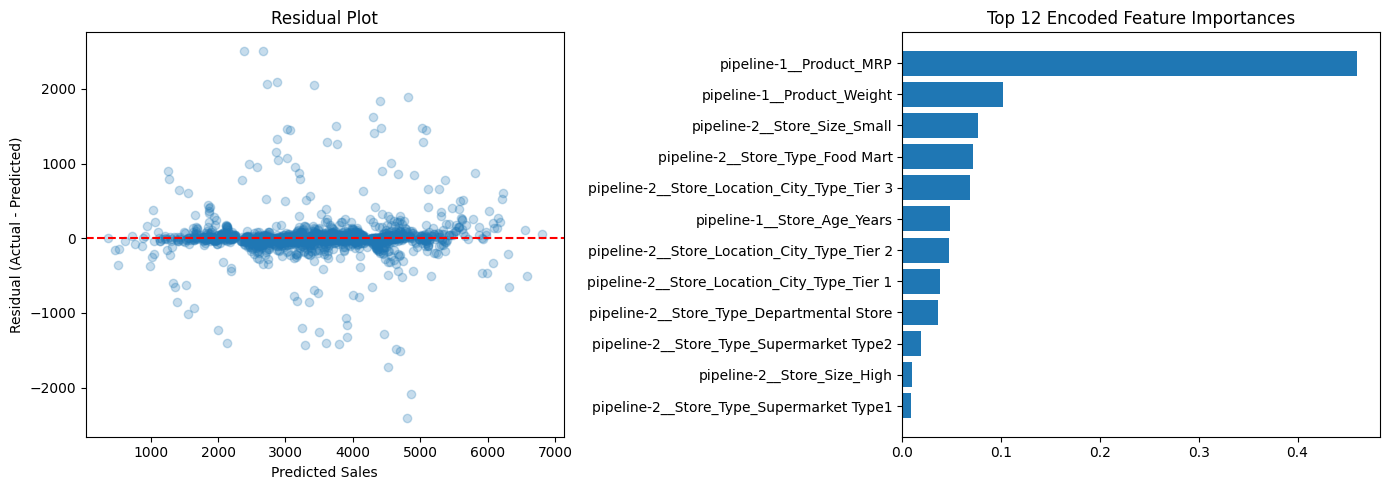


Selected final model: Random Forest
Selected because it has the lowest held-out Test RMSE: 278.1701
Serialized model: /Users/raghu/Python_Projects/Multi_Agentic_AI/backend_files/superkart_model.joblib
Comparison table: /Users/raghu/Python_Projects/Multi_Agentic_AI/backend_files/model_comparison.csv
Observation: residuals should be centered around zero; patterns in the residual plot may indicate nonlinear effects or missing business variables not available in this dataset.


In [13]:
# Compare tuned candidates, analyze residuals, and serialize the final model
comparison = []
for name, search in searches.items():
    pred = search.predict(X_test)
    comparison.append({
        "Model": name,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test MAPE": mean_absolute_percentage_error(y_test, pred),
        "Test R-squared": r2_score(y_test, pred),
        "Test Adj. R-squared": adj_r2_score(X_test, y_test, pred),
        "Best parameters": str(search.best_params_),
    })

comparison_df = pd.DataFrame(comparison).sort_values("Test RMSE")
print(comparison_df.to_string(index=False))

final_model_name = comparison_df.iloc[0]["Model"]
final_model = searches[final_model_name].best_estimator_
final_predictions = final_model.predict(X_test)
residuals = y_test - final_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(final_predictions, residuals, alpha=0.25)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residual Plot")

if final_model_name == "Random Forest":
    importances = final_model.named_steps["model"].feature_importances_
    feature_names = final_model.named_steps["preprocessor"].get_feature_names_out()
    importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values("Importance", ascending=False).head(12)
    axes[1].barh(importance_df["Feature"], importance_df["Importance"])
    axes[1].invert_yaxis()
    axes[1].set_title("Top 12 Encoded Feature Importances")

plt.tight_layout()
plt.show()

model_dir = Path("/Users/raghu/Python_Projects/Multi_Agentic_AI/backend_files")
model_dir.mkdir(parents=True, exist_ok=True)
model_path = model_dir / "superkart_model.joblib"
comparison_path = model_dir / "model_comparison.csv"

joblib.dump(final_model, model_path)
comparison_df.drop(columns="Best parameters").to_csv(comparison_path, index=False)

print("Selected final model:", final_model_name)
print("Serialized model:", model_path)
print("Comparison table:", comparison_path)

**Model Comparison and Selection — Observation**

- Random Forest is selected because it achieved the lowest held-out test RMSE of approximately 278.17.
- The tuned model explains about 93.2% of test-sales variance and records a test MAPE of approximately 3.78%.
- The residual plot is mostly centered around zero, though wider residual variation at higher predicted sales suggests possible heteroscedasticity or missing variables.
- MRP and product weight are among the most important features, while several store size, store type, and city-tier categories provide additional explanatory value.

# **Deployment - Backend**

## Deployment prerequisites

Before deployment, the project creator will need to provide:

- a GitHub repository and account,
- a Personal Access Token only if pushing a private repository over HTTPS,
- Docker Desktop or GitHub Codespaces when container execution is requested,
- public Codespace URLs for ports 7860 and 8501 if inference is to be tested externally.

No API key is required for the current model or Flask endpoint. Credentials must not be committed to the notebook or source files.

## Flask Web Framework

Flask is a lightweight, flexible Python web framework used to build web applications and APIs quickly and easily.

Flask allows you to:
- Create web routes (URLs that users can access)
- Handle HTTP requests and responses
- Build REST APIs to expose machine learning models or other services

In [ ]:
# Flask backend implementation location
from pathlib import Path
backend_path = Path("/Users/raghu/Python_Projects/Multi_Agentic_AI/app.py")
print("Backend implementation:", backend_path)
print("Health endpoint: GET /health")
print("Online endpoint: POST /v1/predict")
print("Batch endpoint: POST /v1/predictbatch")
print("The backend loads the serialized pipeline and performs input validation before inference.")

**Deployment — Backend Observation**

- The Flask backend separates model inference from the notebook and exposes both online and batch prediction endpoints.
- Input field validation is required before prediction so missing or incompatible records do not reach the serialized pipeline.
- No external API key or database credential is required for the current backend implementation.

## Dependencies File

In [ ]:
from pathlib import Path
for name in ["backend_requirements.txt", "frontend_requirements.txt"]:
    path = Path("/Users/raghu/Python_Projects/Multi_Agentic_AI") / name
    print(f"{name}: {path.exists()} -> {path}")

## Dockerfile

In [ ]:
print("Backend Dockerfile: backend_Dockerfile")
print("It copies app.py and backend_files/superkart_model.joblib and exposes port 7860.")

# **Deployment - Frontend**

## Streamlit for Interactive UI

In [ ]:
frontend_path = Path("/Users/raghu/Python_Projects/Multi_Agentic_AI/streamlit_app.py")
print("Frontend implementation:", frontend_path)
print("The Streamlit UI provides online and batch prediction forms.")
print("Set SUPERKART_API_URL only after the Flask URL is created.")

**Deployment — Frontend Observation**

- The Streamlit interface provides a simple human-facing tool for sales-forecast entry and batch CSV upload.
- The frontend depends on the Flask API URL and should therefore be launched after the backend service is reachable.
- Public Codespace ports are needed only when external browser or API access is requested.

## Dependencies File

In [ ]:
print("Frontend dependencies: frontend_requirements.txt")

## Dockerfile

In [ ]:
print("Frontend Dockerfile: frontend_Dockerfile")
print("Default API URL inside the Docker network: http://superkart-backend:7860")

# **Pushing Deployment Files to GitHub**

In [ ]:
# Deployment files and Docker commands:
# docker network create superkart-network
# docker build -f backend_Dockerfile -t superkart-backend .
# docker run -d --name superkart-backend --network superkart-network -p 7860:7860 superkart-backend
# docker build -f frontend_Dockerfile -t superkart-frontend .
# docker run -d --name superkart-frontend --network superkart-network -p 8501:8501 superkart-frontend
print("GitHub push/deployment instructions are prepared in the project files.")

# **Inferencing using Flask API**

As the ***frontend and backend are decoupled***, we can ***access the backend directly for predictions***.
- The decoupling ensures seamless interaction with the deployed model while leveraging the API for scalable inference.

Let's see how to interact with the deployed Flask API running inside a GitHub Codespace to perform **online** and **batch inference** from this Colab notebook.

We will:
1. Send API requests for both online and batch inference.
2. Process and check the model predictions.

**Before running the cells below**, make sure:
- Your Codespace is running with both containers up
- Port 7860 has been set to **Public** in the Codespace Ports tab
- You have copied the forwarded URL for port 7860
- You have also referred the document titled **`Guided Hands-on - Containerized Model Deployment using GitHub Codespaces`** provided

In [ ]:
import json  # To handle JSON formatting for API requests and responses
import requests  # To send HTTP requests to the deployed Flask API

import pandas as pd  # For data manipulation and analysis
import numpy as np  # For numerical computations

In [ ]:
model_root_url = "http://localhost:7860"  # Replace with the public Codespace URL, if deployed

Replace the URL above with the actual forwarded URL from your Codespace's Ports tab. It will look something like `https://organic-space-abcd1234-7860.app.github.dev`. Make sure there is no trailing slash at the end.

This URL is a tunnel that Codespaces creates to route external HTTP requests into your Codespace and to the Flask container running on port 7860.

In [ ]:
model_url = model_root_url + "/v1/predict"  # Endpoint for online (single) inference

Since our model predictions are provided by the following endpoint we created using Flask, we need to invoke the same to make prediction.

> ```@superkart_api.post('/v1/predict')```

In [ ]:
model_batch_url = model_root_url + "/v1/predictbatch"  # Endpoint for batch inference

> ```@superkart_api.post('/v1/predictbatch')```

## Online

**Online Inference:** Sending a single request to the API and receiving an immediate response. This is useful for real-time applications like recommendation systems and fraud detection.  
* This data is sent as a JSON payload in a POST request to the model endpoint.

* The model processes the input features and returns a prediction.

In [ ]:
payload = {
  "Product_Weight": 12.66,
  "Product_Sugar_Content": "Low Sugar",
  "Product_Allocated_Area": 0.027,
  "Product_MRP": 117.08,
  "Store_Size": "Medium",
  "Store_Location_City_Type": "Tier 2",
  "Store_Type": "Supermarket Type2",
  "Product_Id_char": "FD",
  "Store_Age_Years": 16,
  "Product_Type_Category": "Non Perishables"
}

In [ ]:
# Sending a POST request to the model endpoint with the test payload
response = requests.post(model_url, json=payload)

In [ ]:
response

`<Response [200]>` indicates that the HTTP request was successful.  

- `Response` is the object returned by `requests.post()`.  
- `[200]` is the HTTP status code, meaning **OK** (the request was processed successfully).  

In [ ]:
print(response.json())

`response.json()` is used to parse the response body as JSON.  
- If the API returns data in JSON format, `.json()` converts it into a Python dictionary.  
- This allows easy access to specific values using keys.  

## Batch

**Batch Inference:** Sending multiple inputs in a single request, allowing efficient processing of large datasets. This is ideal for analyzing historical data at scale.

In [ ]:
try:
    batch_dataset = pd.read_csv("Batch_Data_SuperKart.csv")
except FileNotFoundError:
    batch_dataset = pd.read_csv("/Users/raghu/Python_Projects/Multi_Agentic_AI/Batch_Data_SuperKart.csv")
print("Batch shape:", batch_dataset.shape)
batch_dataset.head()

**Note**: The batch CSV file must contain all the feature columns expected by the model: `Product_Weight`, `Product_Sugar_Content`, `Product_Allocated_Area`, `Product_MRP`, `Store_Size`, `Store_Location_City_Type`, `Store_Type`, `Product_Id_char`, `Store_Age_Years`, `Product_Type_Category`.

In [ ]:
# Prepare batch input for API request
batch_input = {
    'file': batch_dataset.to_csv(header=True, index=False).encode('utf-8')
}

This code prepares the product data as a **file-like object** to send in an API request (in the `files` parameter of `requests.post`).

- `batch_dataset`: This is a Pandas DataFrame containing the product data loaded from a CSV file.

- `.to_csv(header=True, index=False)`: Converts the DataFrame into a CSV **string**, keeping the column headers (`header=True`) but **excluding the index** (`index=False`).

- `.encode('utf-8')`: Encodes the CSV string into **bytes** (UTF-8 format), which is necessary for sending it over an HTTP request.

- `'file': ...`: Wraps the encoded CSV data in a dictionary with the key `'file'`, which is expected by the Flask backend.

In [ ]:
# Send request to the model API for batch predictions
response = requests.post(
    model_batch_url,  # Model endpoint URL
    files=batch_input
)

This line sends a **POST request** to the deployed model API to perform **batch sales prediction**.

- `requests.post(...)`: This uses the `requests` library to make a **POST** request to a web server (in this case, our API endpoint for batch predictions).

- `model_batch_url`: This is the URL endpoint where the batch prediction API is hosted. It should look like this:\
  `"https://<your-codespace-name>-7860.app.github.dev/v1/predictbatch"`

- `files=batch_input`: This sends the batch data file (e.g., a CSV) as part of the request using the `files` parameter.

- `response`: This is the result of the API call and contains the response from the server, including predicted sales values.

In [ ]:
response

In [ ]:
# Extract predictions from API response
response.text

As we can see, we receive a JSON where each key represents a row index, and the value represents the model's predicted sales for that product.

# **Actionable Insights and Business Recommendations**

- **Inventory planning:** use the expected-sales forecast as a baseline for replenishment priorities, especially for high-MRP products and stores with strong historical sales.
- **Store strategy:** compare forecast accuracy and residual patterns by store type and city tier before setting regional targets.
- **Assortment decisions:** prioritize products with strong positive relationships to MRP and allocated display area, while avoiding over-reliance on correlation alone.
- **Model monitoring:** retrain the selected Random Forest pipeline periodically and trigger review if test RMSE or MAPE degrades beyond an agreed business threshold.
- **Deployment governance:** add authentication, request logging, and rate limiting before production use; the current implementation is suitable for local or controlled testing.